# 01 · Robot and Simulation

A `Robot` is a body in a world. A `Simulation` is the world: it owns time and holds every robot in it.
This notebook puts an SO-101 arm and a Unitree G1 in one world, moves them, films them, and runs the one loop.

![two robots, one world, one clock](media/01/one_world.svg)

Needs `uv pip install -e ".[mujoco,onnx]"` (`onnx` for the G1's standing policy, fetched from the Hugging Face Hub once).

In [1]:
import math
import time
from pathlib import Path

import numpy as np
from PIL import Image

from strands_robots import Description, Policy, Robot, Simulation

MEDIA = Path("media/01") if Path("media").is_dir() else Path("notebooks/media/01")
MEDIA.mkdir(parents=True, exist_ok=True)


def gif(frames, name, size, ms):
    """Save frames as an animated GIF in MEDIA; returns its size in KB."""
    imgs = [Image.fromarray(f).resize(size) for f in frames]
    imgs[0].save(MEDIA / name, save_all=True, append_images=imgs[1:], duration=ms, loop=0)
    return round((MEDIA / name).stat().st_size / 1e3)

## A description, before any world

`Description.load(name)` resolves the model file from the registry and reads joints, actuators and limits from the
model itself. Nothing is simulated yet.

In [2]:
d = Description.load("so101")
print(d.name, "|", d.format, "|", d.category, "|", d.model_path.name)
print("dof", d.dof, "| action_keys", d.action_keys)
print("keyframes", d.keyframes, "| floating base", d.floating)
print("gripper", d.gripper)
print("hardware", d.hardware.driver, d.hardware.lerobot_type, dict(d.hardware.lerobot_norm))
for k, (lo, hi) in d.limits.items():
    print(f"  {k:13s} {math.degrees(lo):7.1f} .. {math.degrees(hi):6.1f} deg")

so101 | mjcf | arm | so101_new_calib.xml
dof 6 | action_keys ('shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper')
keyframes () | floating base False
gripper Gripper(keys=('gripper',), closed='low', open='high')
hardware feetech so101_follower {'*': 'range_m100_100', 'gripper': 'range_0_100'}
  shoulder_pan   -110.0 ..  110.0 deg
  shoulder_lift  -100.0 ..  100.0 deg
  elbow_flex     -100.0 ..   90.0 deg
  wrist_flex      -95.0 ..   95.0 deg
  wrist_roll     -160.0 ..  160.0 deg
  gripper         -10.0 ..  100.0 deg


In [3]:
g = Description.load("g1")
print(g.name, "| dof", g.dof, "| floating base", g.floating, "| keyframes", g.keyframes)

unitree_g1 | dof 29 | floating base True | keyframes ('stand',)


## Two robots, one world

A robot given no `sim=` joins `Simulation.default()`. Both land in the same world: one physics step, one clock.
Ids are unique per world; a second `so101` would be `so101_2`.

In [4]:
arm = Robot("so101")
g1 = Robot("g1", position=[0.7, 0.3, 0], keyframe="stand")
sim = arm.sim
assert sim is g1.sim is Simulation.default()
print(sim)
print(sim.physics, "-> control_dt", sim.physics.control_dt, "s")
print("ids", list(sim.robots))

Simulation('mujoco', physics='native', robots=['so101', 'g1'], t=0.000)
Physics(name='mujoco', timestep=0.002, substeps=10) -> control_dt 0.02 s
ids ['so101', 'g1']


## observe, act, set_pose

`observe()` returns an `Observation`: joints in radians, the base pose (a floating base also reports its velocities),
images. `act()` writes targets for this body and steps the whole world once.

In [5]:
o = g1.observe(images=False)
print("g1 pelvis at", o.pose.position.round(3), "| moving at", o.pose.linear_velocity.round(3), "m/s")

for _ in range(40):
    o = arm.act({"shoulder_pan": 0.5, "shoulder_lift": -0.4, "elbow_flex": 0.5})
print(f"after 40 acts: t = {sim.time:.2f} s; the G1 reads the same clock: {g1.observe(images=False).t:.2f} s")
print({k: round(v, 3) for k, v in o.joints.as_dict().items()})

g1 pelvis at [0.7  0.3  0.79] | moving at [0. 0. 0.] m/s
after 40 acts: t = 0.80 s; the G1 reads the same clock: 0.80 s
{'shoulder_pan': 0.502, 'shoulder_lift': -0.379, 'elbow_flex': 0.526, 'wrist_flex': 0.007, 'wrist_roll': 0.0, 'gripper': -0.0}


A joint an action leaves out holds its last target. Here only `elbow_flex` is named for 200 steps; `shoulder_lift`
stays where the cell above put it instead of sagging under gravity.

In [6]:
lift0 = arm.observe(images=False)["shoulder_lift"]
for _ in range(200):
    o = arm.act({"elbow_flex": 0.4})
print(f"shoulder_lift {lift0:.3f} -> {o['shoulder_lift']:.3f} rad after 200 steps (drift {abs(o['shoulder_lift'] - lift0):.4f})")
print("gripper (a link) at", sim.pose("so101/gripper").position.round(3), "m")

shoulder_lift -0.379 -> -0.379 rad after 200 steps (drift 0.0001)
gripper (a link) at [-0.081 -0.208  0.26 ] m


An unknown joint is refused by name; a target past a limit is clipped to it.

In [7]:
try:
    arm.act({"elbo_flex": 0.1})
except KeyError as e:
    print("KeyError:", e)
targets = arm.coerce({"elbow_flex": 9.0})
print(f"elbow_flex=9.0 becomes the target {targets[2]:.3f} rad, its upper limit")

KeyError: "unknown joint(s) ['elbo_flex'] for so101; action_keys are ['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']"
elbow_flex=9.0 becomes the target 1.571 rad, its upper limit


`set_pose` teleports a base. It is a scene change (`revision` bumps); time does not move and joint state survives.

In [8]:
rev, t = sim.revision, sim.time
arm.set_pose(position=[0.0, -0.05, 0.0])
print("arm base", arm.pose.position, "| revision", rev, "->", sim.revision, "| time", round(t, 2), "->", round(sim.time, 2))

arm base [ 0.   -0.05  0.  ] | revision 2 -> 3 | time 4.8 -> 4.8


## Cameras

A world camera sees the scene. A camera attached to a robot (`attach="so101"`, its base) or to one of its links
(`attach="so101/gripper"`, a wrist view) moves with it and appears in that robot's observations.

links: ['base', 'shoulder', 'upper_arm', 'lower_arm', 'wrist', 'gripper', 'moving_jaw_so101_v1']


arm.observe().images: {'wrist': (320, 480, 3)}
g1.observe().images: []


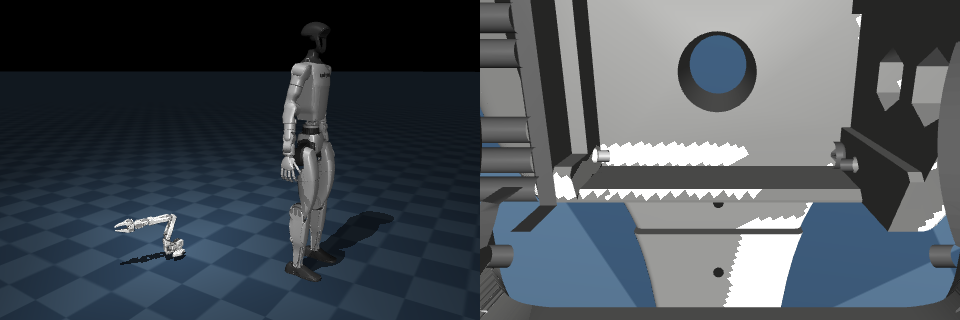

In [9]:
print("links:", sim.describe()["robots"]["so101"]["links"])
sim.camera("front", position=[1.5, -1.6, 1.1], target=[0.35, 0.15, 0.6], size=(480, 320))
sim.camera("wrist", position=[0.035, 0, -0.02], target=[-0.2, 0, -0.09], attach="so101/gripper", size=(480, 320))
o = arm.observe()
print("arm.observe().images:", {k: v.shape for k, v in o.images.items()})
print("g1.observe().images:", list(g1.observe().images))
Image.fromarray(np.hstack([sim.render("front"), o.images["wrist"]]))

## Both robots move: `Simulation.run`

`sim.run({robot: policy, ...})` drives many robots in lock-step: every robot observes, every policy acts, then the
world steps once. The arm runs a plain function. The G1 runs `Policy("holosoma")`, an ONNX whole-body controller
that keeps it standing (05 covers policies).

In [10]:
frames = []


def wave(obs):
    if round(obs.t * 50) % 5 == 0:
        frames.append(sim.render("front"))
    return {"shoulder_pan": 0.9 * math.sin(2 * obs.t), "elbow_flex": 0.5 + 0.5 * math.sin(3 * obs.t), "shoulder_lift": -0.4}


results = sim.run({arm: wave, g1: Policy("holosoma")}, hz=50, seconds=6)
for rid, r in results.items():
    print(f"{rid:11s} {r.steps} steps | {r.seconds:.2f} s sim | {r.hz_target:g} Hz | stopped_by={r.stopped_by}")
print(f"G1 pelvis height after 6 s: {g1.pose.position[2]:.3f} m | {len(frames)} frames")
print("gif", gif(frames, "two_robots.gif", (360, 240), 100), "KB")

so101       300 steps | 6.00 s sim | 50 Hz | stopped_by=seconds
g1          300 steps | 6.00 s sim | 50 Hz | stopped_by=seconds
G1 pelvis height after 6 s: 0.766 m | 60 frames


gif 2192 KB


![the arm waves while the G1 stands](media/01/two_robots.gif)

One clock: both results end at the same sim time.

In [11]:
print({rid: round(r.final.t, 4) for rid, r in results.items()})

{'so101': 10.8, 'g1': 10.8}


## The one loop: `Robot.run`

`robot.run(policy, hz=, seconds= | steps= | stop_when=)` is observe -> policy -> act, written once. A bare callable is a
policy. In a world, `hz` sets how many physics steps each act covers and time is sim time, so it runs as fast as the
machine allows (`realtime=True` paces it to the wall clock). It returns a `RunResult`.

![observe, policy, act, until a limit](media/01/run_loop.svg)

In [12]:
r = arm.run(lambda obs: {"shoulder_pan": -0.6, "elbow_flex": 0.2}, hz=50, seconds=2)
print(f"steps={r.steps} seconds={r.seconds:.2f} hz_target={r.hz_target:g} hz_achieved={r.hz_achieved:.1f}")
print(f"stopped_by={r.stopped_by} recorded={r.recorded} fault={r.fault} deadline_misses={r.deadline_misses}")
print("final", {k: round(v, 3) for k, v in r.final.joints.as_dict().items()})

steps=100 seconds=2.00 hz_target=50 hz_achieved=50.0
stopped_by=seconds recorded=None fault=None deadline_misses=0
final {'shoulder_pan': -0.601, 'shoulder_lift': -0.379, 'elbow_flex': 0.225, 'wrist_flex': 0.006, 'wrist_roll': 0.0, 'gripper': -0.0}


The policy named two joints; the other four held their last targets (`shoulder_lift` is still where the wave left it).
A run limited by `seconds=` says `stopped_by="seconds"`.

`stop_when` ends on a condition instead of a count. A run with no limit at all is refused.

In [13]:
r = arm.run(lambda obs: {"gripper": 1.2}, hz=30, stop_when=lambda obs: obs["gripper"] > 1.0)
print(f"stop_when: {r.steps} steps, stopped_by={r.stopped_by}, gripper={r.final['gripper']:.3f}")
try:
    arm.run(lambda obs: {})
except ValueError as e:
    print("ValueError:", e)

stop_when: 7 steps, stopped_by=stop_when, gripper=1.052
ValueError: run needs seconds=, steps= or stop_when=


`start()` runs the same loop on a background thread; `stop()` ends it and returns its `RunResult`.

In [14]:
task = arm.start(lambda obs: {"wrist_roll": math.sin(obs.t)}, hz=50, realtime=True, seconds=30)
time.sleep(0.5)
r = arm.stop()
print(f"start/stop: {r.steps} steps, {r.seconds:.2f} s sim, stopped_by={r.stopped_by}")

start/stop: 20 steps, 0.40 s sim, stopped_by=stopped


## Manual time

Inside `with sim.manual_time():`, `act()` only writes targets and the caller decides when the world steps.

In [15]:
with sim.manual_time():
    t0 = sim.time
    arm.act({"shoulder_pan": 0.0})
    arm.act({"shoulder_pan": 0.0})
    print(f"two acts: time {t0:.3f} -> {sim.time:.3f}")
    sim.step(50)
    print(f"sim.step(50): time -> {sim.time:.3f} (50 x {sim.physics.timestep} s)")

two acts: time 13.438 -> 13.438
sim.step(50): time -> 13.538 (50 x 0.002 s)


## The whole world as data

`describe()` is JSON-safe: what an agent tool and the dashboard read.

In [16]:
w = sim.describe()
print({k: w[k] for k in ("backend", "physics", "time", "revision", "manual_time")})
print({rid: (r["dof"], [round(x, 2) for x in r["pose"]["position"]]) for rid, r in w["robots"].items()})
print(w["cameras"])
sim.close()

{'backend': 'mujoco', 'physics': {'name': 'mujoco', 'timestep': 0.002, 'substeps': 10, 'envs': 1, 'deterministic': True}, 'time': 13.53800000000119, 'revision': 5, 'manual_time': False}
{'so101': (6, [0.0, -0.05, 0.0]), 'g1': (29, [0.66, 0.29, 0.76])}
[{'name': 'front', 'size': [480, 320], 'attach': None}, {'name': 'wrist', 'size': [480, 320], 'attach': 'so101/gripper'}]


## Next

[02](02_recording.ipynb): record a run as a LeRobot dataset and read it back.